# Phase 5 - Super-Clustering Contextual (Transformer v3 Tuned)

Version mejorada enfocada en robustez real:
- encoder MLM estable (sin sobrecargar el objetivo),
- seleccion de K robusta multi-seed + señal economica en validacion temporal,
- comparacion contra v2.


In [1]:
import json
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 240)
pd.set_option('display.width', 260)


In [2]:
# =========================
# Config
# =========================
SYMBOL = 'GBPUSD'
MODEL_TAG = 'v3_tuned'
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

# Transformer
D_MODEL = 112
N_HEAD = 4
N_LAYERS = 4
FF_DIM = 224
DROPOUT = 0.10
EMB_DIM = 64
DELTA_BINS = 24
SIGN_BINS = 3
MASK_PROB = 0.18
BATCH_SIZE = 64
EPOCHS = 55
LR = 6e-4
WEIGHT_DECAY = 1e-4
PATIENCE = 12
LABEL_SMOOTH = 0.03

# Super-clustering
K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 40
HORIZON_HOURS = 24
MIN_CLUSTER_N = 20

IN_DIR = Path('./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2')
WINDOWS_PATH = IN_DIR / 'GBPUSD_sequence_windows_full_len32.parquet'
VOCAB_PATH = IN_DIR / 'GBPUSD_token_vocabulary.json'
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/GBPUSD.parquet')

PREV_SUMMARY_PATH = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v2/GBPUSD_superclustering_summary.json')

OUT_DIR = Path('./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned')
OUT_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = OUT_DIR / 'GBPUSD_transformer_context_train_history_v3.csv'
ENCODER_PT = OUT_DIR / 'GBPUSD_transformer_context_encoder_v3.pt'
MODEL_SELECTION_CSV = OUT_DIR / 'GBPUSD_superclustering_model_selection_v3.csv'
EMB_PQ = OUT_DIR / 'GBPUSD_context_window_embeddings_v3.parquet'
EMB_CSV = OUT_DIR / 'GBPUSD_context_window_embeddings_v3.csv'
PROFILE_CSV = OUT_DIR / 'GBPUSD_context_regime_profile_v3.csv'
TRANS_CSV = OUT_DIR / 'GBPUSD_context_regime_transition_matrix_v3.csv'
SUMMARY_JSON = OUT_DIR / 'GBPUSD_superclustering_summary_v3.json'

print('WINDOWS_PATH =', WINDOWS_PATH)
print('DEVICE =', DEVICE)
print('OUT_DIR =', OUT_DIR)


WINDOWS_PATH = ./phases/phase05_context_sequencing/output_secuenciacion_GBPUSD_v2/GBPUSD_sequence_windows_full_len32.parquet
DEVICE = cuda
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned


In [3]:
# =========================
# Reproducibilidad + helpers
# =========================
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001

def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test

def delta_to_bins(delta_arr: np.ndarray, delta_max: float, n_bins: int):
    x = np.asarray(delta_arr, dtype=float)
    x = np.clip(x, 0.0, max(1e-6, float(delta_max)))
    z = np.log1p(x) / np.log1p(max(1e-6, float(delta_max)))
    b = np.floor(z * (n_bins - 1 + 1e-12)).astype(int)
    b = np.clip(b, 0, n_bins - 1)
    return b

def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')

    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out

def make_masked_inputs(x: torch.Tensor, vocab_size: int, mask_id: int, mask_prob: float = 0.15):
    labels = x.clone()
    prob = torch.rand_like(x.float())
    masked = prob < mask_prob

    labels[~masked] = -100
    x_in = x.clone()

    if masked.any():
        r = torch.rand_like(x.float())
        mask_pos = masked & (r < 0.8)
        rand_pos = masked & (r >= 0.8) & (r < 0.9)

        x_in[mask_pos] = mask_id
        if rand_pos.any():
            rnd = torch.randint(low=0, high=vocab_size, size=(rand_pos.sum().item(),), device=x.device)
            x_in[rand_pos] = rnd

    return x_in, labels


def zscore_col(x: pd.Series, eps: float = 1e-9):
    m = float(x.mean())
    s = float(x.std(ddof=0))
    if not np.isfinite(s) or s < eps:
        return pd.Series(np.zeros(len(x)), index=x.index, dtype=float)
    return (x - m) / (s + eps)


In [4]:
# =========================
# Load sequence windows
# =========================
for p in [WINDOWS_PATH, VOCAB_PATH, PRICE_PATH]:
    if not p.exists():
        raise FileNotFoundError(f'Missing file: {p}')

W = pd.read_parquet(WINDOWS_PATH).copy()
W['start_ts'] = pd.to_datetime(W['start_ts'], errors='coerce')
W['end_ts'] = pd.to_datetime(W['end_ts'], errors='coerce')
W = W.sort_values(['start_ts', 'window_id']).reset_index(drop=True)

vocab = json.loads(VOCAB_PATH.read_text())
token_to_id = {str(k): int(v) for k, v in vocab['token_to_id'].items()}
id_to_token = {int(v): str(k) for k, v in token_to_id.items()}
vocab_size = len(token_to_id)
mask_id = vocab_size

# arrays
tok = np.vstack([np.array([token_to_id[str(t)] for t in row], dtype=np.int64) for row in W['token_seq']])
dlt = np.vstack([np.asarray(row, dtype=float) for row in W['delta_h_seq']])
sgn = np.vstack([np.asarray(row, dtype=int) for row in W['move_sign_seq']])
sgn = np.clip(sgn + 1, 0, 2).astype(np.int64)  # -1,0,1 -> 0,1,2

if tok.shape[1] != SEQ_LEN:
    raise RuntimeError(f'Expected seq len {SEQ_LEN}, got {tok.shape[1]}')

idx_train, idx_val, idx_test = temporal_split(len(W), TRAIN_RATIO, VAL_RATIO)
split = np.array(['train'] * len(W), dtype=object)
split[idx_val] = 'val'
split[idx_test] = 'test'
W['split'] = split

# delta bins calibrated on train only
delta_max = float(np.nanquantile(dlt[idx_train].reshape(-1), 0.99))
delta_max = max(1.0, delta_max)
dlt_bin = delta_to_bins(dlt, delta_max=delta_max, n_bins=DELTA_BINS).astype(np.int64)

print('windows =', len(W), '| vocab_size =', vocab_size)
print('split counts:')
print(W['split'].value_counts().to_string())
print('delta_max(train p99) =', round(delta_max, 3))
display(W.head(3))


windows = 1605 | vocab_size = 9
split counts:
split
train    1123
val       241
test      241
delta_max(train p99) = 780.0


,window_id,symbol,seq_len,start_ts,end_ts,token_seq,cluster_seq,delta_h_seq,move_sign_seq,split
0,0,GBPUSD,32,2000-05-31 10:00:00,2000-11-01 23:00:00,"[c03, c01, c08, c07, c01, c01, c02, c01, c08, ...","[3, 1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, ...","[0.0, 40.0, 144.0, 114.0, 50.0, 336.0, 319.0, ...","[1, 1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, ...",train
1,1,GBPUSD,32,2000-06-02 02:00:00,2000-11-02 23:00:00,"[c01, c08, c07, c01, c01, c02, c01, c08, c07, ...","[1, 8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, ...","[40.0, 144.0, 114.0, 50.0, 336.0, 319.0, 189.0...","[1, -1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, ...",train
2,2,GBPUSD,32,2000-06-08 02:00:00,2000-11-06 02:00:00,"[c08, c07, c01, c01, c02, c01, c08, c07, c01, ...","[8, 7, 1, 1, 2, 1, 8, 7, 1, 2, 2, 7, 2, 4, 7, ...","[144.0, 114.0, 50.0, 336.0, 319.0, 189.0, 192....","[-1, -1, 1, 1, -1, 1, -1, 1, 1, -1, -1, 1, -1,...",train


In [5]:
# =========================
# Dataset + model
# =========================
class SeqDataset(Dataset):
    def __init__(self, tok_arr, dlt_arr, sgn_arr, indices):
        idx = np.asarray(indices, dtype=int)
        self.tok = torch.from_numpy(tok_arr[idx]).long()
        self.dlt = torch.from_numpy(dlt_arr[idx]).long()
        self.sgn = torch.from_numpy(sgn_arr[idx]).long()

    def __len__(self):
        return len(self.tok)

    def __getitem__(self, i):
        return self.tok[i], self.dlt[i], self.sgn[i]


class ContextTransformer(nn.Module):
    def __init__(self, vocab_size, mask_id, seq_len, d_model, n_head, n_layers, ff_dim, dropout, delta_bins, sign_bins, emb_dim):
        super().__init__()
        self.vocab_size = int(vocab_size)
        self.mask_id = int(mask_id)
        self.seq_len = int(seq_len)

        self.token_emb = nn.Embedding(vocab_size + 1, d_model)  # +1 mask token
        self.delta_emb = nn.Embedding(delta_bins, d_model)
        self.sign_emb = nn.Embedding(sign_bins, d_model)
        self.pos_emb = nn.Parameter(torch.randn(1, seq_len, d_model) * 0.02)

        enc_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_head,
            dim_feedforward=ff_dim,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
        )
        self.encoder = nn.TransformerEncoder(enc_layer, num_layers=n_layers)

        self.to_emb = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, emb_dim),
        )
        self.mlm_head = nn.Linear(d_model, vocab_size)

    def forward(self, tok_ids, dlt_ids, sgn_ids):
        h = self.token_emb(tok_ids) + self.delta_emb(dlt_ids) + self.sign_emb(sgn_ids)
        h = h + self.pos_emb[:, :h.shape[1], :]
        h = self.encoder(h)
        logits = self.mlm_head(h)

        pooled = h.mean(dim=1)
        z = self.to_emb(pooled)
        return logits, z


In [6]:
# =========================
# Train contextual encoder (MLM)
# =========================
pin = DEVICE == 'cuda'
train_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_train), batch_size=BATCH_SIZE, shuffle=True, pin_memory=pin)
val_loader = DataLoader(SeqDataset(tok, dlt_bin, sgn, idx_val), batch_size=BATCH_SIZE, shuffle=False, pin_memory=pin)

model = ContextTransformer(
    vocab_size=vocab_size,
    mask_id=mask_id,
    seq_len=SEQ_LEN,
    d_model=D_MODEL,
    n_head=N_HEAD,
    n_layers=N_LAYERS,
    ff_dim=FF_DIM,
    dropout=DROPOUT,
    delta_bins=DELTA_BINS,
    sign_bins=SIGN_BINS,
    emb_dim=EMB_DIM,
).to(DEVICE)

criterion = nn.CrossEntropyLoss(ignore_index=-100, label_smoothing=LABEL_SMOOTH)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=LR * 0.05)

history = []
best_val = float('inf')
best_state = None
bad = 0

for ep in range(1, EPOCHS + 1):
    model.train()
    tr_losses = []

    for xb_tok, xb_dlt, xb_sgn in train_loader:
        xb_tok = xb_tok.to(DEVICE, non_blocking=True)
        xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
        xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)

        x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)

        opt.zero_grad(set_to_none=True)
        logits, _ = model(x_in, xb_dlt, xb_sgn)
        loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        tr_losses.append(float(loss.detach().cpu().item()))

    sched.step()
    tr = float(np.mean(tr_losses)) if tr_losses else np.nan

    model.eval()
    va_losses = []
    with torch.no_grad():
        for xb_tok, xb_dlt, xb_sgn in val_loader:
            xb_tok = xb_tok.to(DEVICE, non_blocking=True)
            xb_dlt = xb_dlt.to(DEVICE, non_blocking=True)
            xb_sgn = xb_sgn.to(DEVICE, non_blocking=True)
            x_in, y_lbl = make_masked_inputs(xb_tok, vocab_size=vocab_size, mask_id=mask_id, mask_prob=MASK_PROB)
            logits, _ = model(x_in, xb_dlt, xb_sgn)
            loss = criterion(logits.reshape(-1, vocab_size), y_lbl.reshape(-1))
            va_losses.append(float(loss.detach().cpu().item()))

    va = float(np.mean(va_losses)) if va_losses else np.nan

    if np.isfinite(va) and va < best_val - 1e-6:
        best_val = va
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        bad = 0
    else:
        bad += 1

    history.append({'epoch': ep, 'train_loss': tr, 'val_loss': va, 'lr': opt.param_groups[0]['lr']})

    if ep == 1 or ep % 5 == 0 or ep == EPOCHS:
        print(f'ep={ep:03d} train={tr:.6f} val={va:.6f} lr={opt.param_groups[0]["lr"]:.6g}')

    if bad >= PATIENCE and ep >= 15:
        print(f'Early stopping at ep={ep}')
        break

if best_state is not None:
    model.load_state_dict(best_state)

torch.save({'state_dict': model.state_dict(), 'config': {
    'seq_len': SEQ_LEN, 'd_model': D_MODEL, 'n_head': N_HEAD, 'n_layers': N_LAYERS,
    'ff_dim': FF_DIM, 'dropout': DROPOUT, 'emb_dim': EMB_DIM, 'delta_bins': DELTA_BINS,
    'sign_bins': SIGN_BINS, 'vocab_size': vocab_size, 'mask_id': mask_id, 'delta_max': delta_max,
}}, ENCODER_PT)

HIST = pd.DataFrame(history)
HIST.to_csv(HISTORY_CSV, index=False)

print('best_val_mlm =', best_val)
print('saved encoder =', ENCODER_PT)
print('saved history =', HISTORY_CSV)


ep=001 train=1.717420 val=1.493302 lr=0.000599535


ep=005 train=1.372305 val=1.488456 lr=0.000588455


ep=010 train=1.218578 val=1.730256 lr=0.000554757


ep=015 train=1.050128 val=1.938025 lr=0.000501635
Early stopping at ep=15
best_val_mlm = 1.437929630279541
saved encoder = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned/GBPUSD_transformer_context_encoder_v3.pt
saved history = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned/GBPUSD_transformer_context_train_history_v3.csv


In [7]:
# =========================
# Infer contextual embeddings
# =========================
model.eval()

def encode_all(tok_arr, dlt_arr, sgn_arr, bs=256):
    out = []
    with torch.no_grad():
        for i in range(0, len(tok_arr), bs):
            xb_tok = torch.from_numpy(tok_arr[i:i+bs]).long().to(DEVICE)
            xb_dlt = torch.from_numpy(dlt_arr[i:i+bs]).long().to(DEVICE)
            xb_sgn = torch.from_numpy(sgn_arr[i:i+bs]).long().to(DEVICE)
            _, z = model(xb_tok, xb_dlt, xb_sgn)
            out.append(z.detach().cpu().numpy())
    return np.vstack(out).astype(np.float32)

Z = encode_all(tok, dlt_bin, sgn)
print('Z shape =', Z.shape)


Z shape = (1605, 64)


In [8]:
# =========================
# Super-clustering selection (robust + economic val)
# =========================
scaler = StandardScaler()
Z_train = scaler.fit_transform(Z[idx_train])
Z_val = scaler.transform(Z[idx_val])

PX_SEL = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
PX_SEL['timestamp'] = pd.to_datetime(PX_SEL['timestamp'], errors='coerce')
PX_SEL['close'] = pd.to_numeric(PX_SEL['close'], errors='coerce')
PX_SEL = PX_SEL.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

ret_val = compute_forward_pips(PX_SEL, W.iloc[idx_val]['end_ts'], symbol=SYMBOL, horizon_hours=HORIZON_HOURS)

rows = []
for k in K_CANDIDATES:
    seed_labels = {}
    sils, chs, dbs = [], [], []

    for sd in KMEANS_SEEDS:
        km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
        km.fit(Z_train)
        lv = km.predict(Z_val)
        seed_labels[sd] = lv

        if len(np.unique(lv)) >= 2 and len(lv) > k:
            sils.append(float(silhouette_score(Z_val, lv)))
            chs.append(float(calinski_harabasz_score(Z_val, lv)))
            dbs.append(float(davies_bouldin_score(Z_val, lv)))

    aris = []
    seeds = list(seed_labels.keys())
    for i in range(len(seeds)):
        for j in range(i + 1, len(seeds)):
            aris.append(float(adjusted_rand_score(seed_labels[seeds[i]], seed_labels[seeds[j]])))

    # val economic separation using canonical seed 42
    lv = seed_labels[42]
    ok = np.isfinite(ret_val)
    groups = []
    for cid in np.unique(lv[ok]):
        x = ret_val[ok][lv[ok] == cid]
        if len(x) >= MIN_CLUSTER_N:
            groups.append(x)

    val_kw = np.nan
    val_eta2 = np.nan
    if len(groups) >= 2:
        val_kw = float(kruskal(*groups).pvalue)
        all_vals = np.concatenate(groups)
        gm = np.mean(all_vals)
        ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
        sst = np.sum((all_vals - gm) ** 2)
        val_eta2 = float(ssb / sst) if sst > 0 else np.nan

    rows.append({
        'k': int(k),
        'sil_val_mean': float(np.mean(sils)) if len(sils) else np.nan,
        'ch_val_mean': float(np.mean(chs)) if len(chs) else np.nan,
        'db_val_mean': float(np.mean(dbs)) if len(dbs) else np.nan,
        'stability_ari_mean': float(np.mean(aris)) if len(aris) else np.nan,
        'val_kw_p': val_kw,
        'val_eta2': val_eta2,
    })

SEL = pd.DataFrame(rows)
SEL['z_sil'] = zscore_col(SEL['sil_val_mean'])
SEL['z_ch'] = zscore_col(SEL['ch_val_mean'])
SEL['z_db'] = zscore_col(SEL['db_val_mean'])
SEL['z_ari'] = zscore_col(SEL['stability_ari_mean'])
SEL['z_val_eta2'] = zscore_col(SEL['val_eta2'].fillna(0.0))
SEL['robust_score'] = SEL['z_sil'] + 0.8 * SEL['z_ch'] - 0.8 * SEL['z_db'] + 0.6 * SEL['z_ari'] + 0.9 * SEL['z_val_eta2']
SEL = SEL.sort_values('robust_score', ascending=False, na_position='last').reset_index(drop=True)
SEL.to_csv(MODEL_SELECTION_CSV, index=False)
BEST_K = int(SEL.iloc[0]['k'])

print('BEST_K =', BEST_K)
display(SEL)


BEST_K = 8


,k,sil_val_mean,ch_val_mean,db_val_mean,stability_ari_mean,val_kw_p,val_eta2,z_sil,z_ch,z_db,z_ari,z_val_eta2,robust_score
0,8,0.100630,32.423869,1.424467,0.951220,0.357518,0.019114,0.983766,0.511364,-0.906723,0.783904,1.842055,4.246428
1,7,0.083193,35.851152,1.421410,0.962479,0.909510,0.005724,0.152911,1.741639,-0.920773,0.874465,-0.585586,2.280492
2,6,0.082055,32.384437,1.802515,0.966070,0.776876,0.007263,0.098689,0.497209,0.830756,0.903346,-0.306641,0.097882
3,5,0.109758,33.505679,2.014207,0.845521,0.818513,0.002891,1.418726,0.899696,1.803674,-0.066218,-1.099224,-0.333488
4,11,0.091673,31.954918,1.624558,0.601814,0.856287,0.008993,0.556999,0.343027,0.012878,-2.026314,0.007062,-0.388315
5,12,0.034283,28.863329,1.408771,0.832800,0.573913,0.015830,-2.177637,-0.766746,-0.978858,-0.168524,1.246660,-0.987067
6,10,0.059783,28.047567,1.424676,0.677112,0.638552,0.012851,-0.962558,-1.059576,-0.905760,-1.420698,0.706567,-1.302120
7,9,0.078199,26.626476,1.580620,0.910823,0.936673,0.005981,-0.085032,-1.569698,-0.189054,0.459002,-0.539059,-1.399299
8,4,0.080281,29.336439,1.894576,0.935943,0.897474,0.001939,0.014136,-0.596916,1.253860,0.661037,-1.271835,-2.214513


In [9]:
# =========================
# Final clustering + regime profiling
# =========================
# fit on train+val for final assignment
idx_trainval = np.concatenate([idx_train, idx_val])
Z_trainval = scaler.fit_transform(Z[idx_trainval])
Z_all = scaler.transform(Z)

KM = KMeans(n_clusters=BEST_K, n_init=N_INIT_KMEANS, random_state=SEED)
KM.fit(Z_trainval)
reg = KM.predict(Z_all)
dist = KM.transform(Z_all).min(axis=1)

OUT = W[['window_id', 'symbol', 'start_ts', 'end_ts', 'split']].copy()
OUT['regime_id'] = reg.astype(int)
OUT['regime_dist'] = dist.astype(float)
OUT['regime_token'] = OUT['regime_id'].map(lambda x: f'r{x:02d}')

for j in range(Z.shape[1]):
    OUT[f'ctx_emb_{j:03d}'] = Z[:, j]

# economic profile using forward return from end_ts
PX = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

OUT['ret_fwd_24h_pips'] = compute_forward_pips(PX, OUT['end_ts'], symbol=SYMBOL, horizon_hours=HORIZON_HOURS)

test_mask = OUT['split'] == 'test'
test_df = OUT.loc[test_mask].copy()

prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
        .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
        .reset_index())
prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

# significance
groups = []
for rid, g in test_df.groupby('regime_id'):
    x = g['ret_fwd_24h_pips'].dropna().to_numpy()
    if len(x) >= MIN_CLUSTER_N:
        groups.append(x)

kw_p = np.nan
anova_p = np.nan
eta2 = np.nan
if len(groups) >= 2:
    kw_p = float(kruskal(*groups).pvalue)
    anova_p = float(f_oneway(*groups).pvalue)
    all_vals = np.concatenate(groups)
    gm = np.mean(all_vals)
    ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
    sst = np.sum((all_vals - gm) ** 2)
    eta2 = float(ssb / sst) if sst > 0 else np.nan

# regime transitions on full sequence
tmp = OUT.sort_values('start_ts').reset_index(drop=True)
tr = pd.crosstab(tmp['regime_token'], tmp['regime_token'].shift(-1)).fillna(0)
tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

OUT.to_parquet(EMB_PQ, index=False)
OUT.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'model_tag': MODEL_TAG,
    'n_windows': int(len(OUT)),
    'split_counts': {k: int(v) for k, v in OUT['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'best_k_robust_score': float(SEL.iloc[0]['robust_score']),
    'best_k_val_eta2': None if not np.isfinite(SEL.iloc[0]['val_eta2']) else float(SEL.iloc[0]['val_eta2']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved embeddings =', EMB_PQ)
print('saved profile =', PROFILE_CSV)
print('saved transitions =', TRANS_CSV)
print('BEST_K =', BEST_K, '| kw_p =', kw_p, '| eta2 =', eta2)
display(prof)


saved embeddings = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned/GBPUSD_context_window_embeddings_v3.parquet
saved profile = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned/GBPUSD_context_regime_profile_v3.csv
saved transitions = ./phases/phase05_context_sequencing/output_superclustering_contextual_GBPUSD_v3_tuned/GBPUSD_context_regime_transition_matrix_v3.csv
BEST_K = 8 | kw_p = 0.18323260762509344 | eta2 = 0.023918484772151923


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,7,57,-13.619306,-17.899275,154.975787,-0.087880
1,5,57,-15.864958,-8.499622,101.484071,-0.156330
2,4,49,-0.920369,9.499788,87.764038,-0.010487
3,0,23,-59.978288,-59.399605,92.155672,-0.650837
4,6,21,5.400067,-6.399155,94.136992,0.057364
5,1,14,53.678496,46.499968,123.240893,0.435558
6,3,14,13.564144,-6.450415,130.657270,0.103815
7,2,6,80.966949,120.750666,105.357794,0.768495


In [10]:
# =========================
# Compare vs previous v2
# =========================
if PREV_SUMMARY_PATH.exists():
    prev = json.loads(PREV_SUMMARY_PATH.read_text())
    curr = json.loads(SUMMARY_JSON.read_text())
    CMP = pd.DataFrame([
        {'metric': 'best_k', 'v2': prev.get('best_k'), 'v3_tuned': curr.get('best_k')},
        {'metric': 'kw_pvalue_test', 'v2': prev.get('kw_pvalue_test'), 'v3_tuned': curr.get('kw_pvalue_test')},
        {'metric': 'anova_pvalue_test', 'v2': prev.get('anova_pvalue_test'), 'v3_tuned': curr.get('anova_pvalue_test')},
        {'metric': 'eta2_test', 'v2': prev.get('eta2_test'), 'v3_tuned': curr.get('eta2_test')},
    ])
    display(CMP)
else:
    print('No previous summary found at:', PREV_SUMMARY_PATH)


,metric,v2,v3_tuned
0,best_k,6.000000,8.000000
1,kw_pvalue_test,0.004396,0.183233
2,anova_pvalue_test,0.004857,0.296199
3,eta2_test,0.063914,0.023918


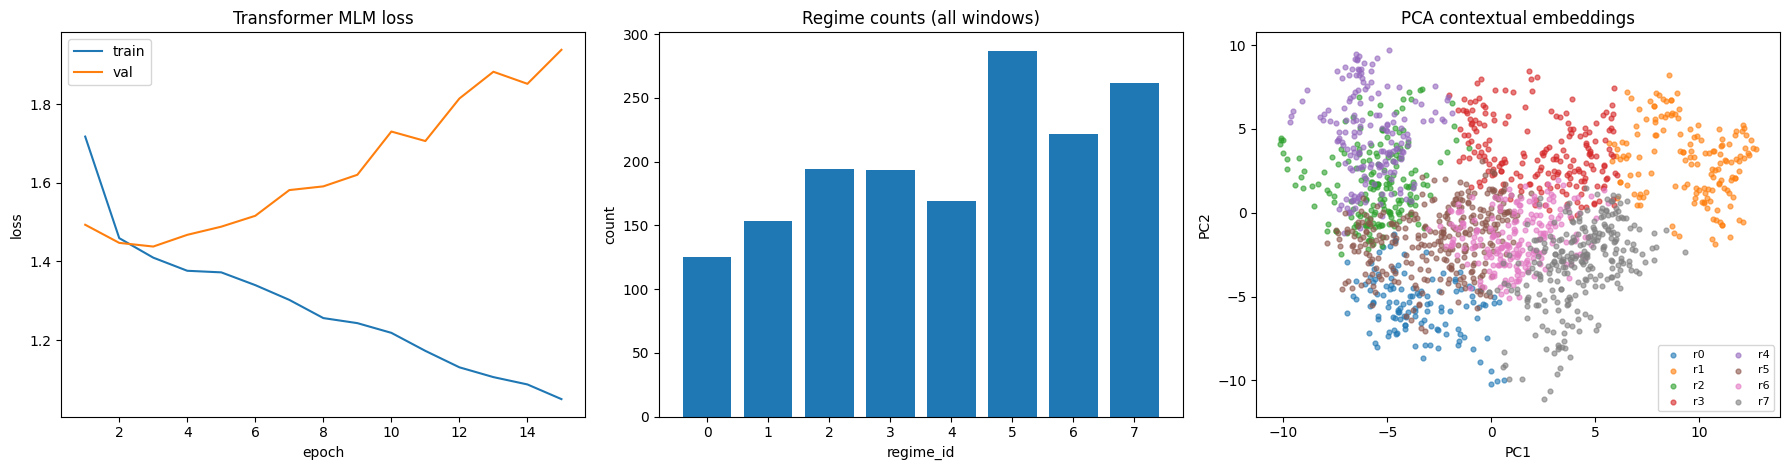

In [11]:
# =========================
# Diagnostics
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# 1) training curve
axes[0].plot(HIST['epoch'], HIST['train_loss'], label='train')
axes[0].plot(HIST['epoch'], HIST['val_loss'], label='val')
axes[0].set_title('Transformer MLM loss')
axes[0].set_xlabel('epoch')
axes[0].set_ylabel('loss')
axes[0].legend()

# 2) regime counts
cnt = OUT['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (all windows)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

# 3) PCA
pca = PCA(n_components=2, random_state=SEED)
xy = pca.fit_transform(Z_all)
for rid in sorted(np.unique(OUT['regime_id'])):
    m = OUT['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=12, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()


## Artefactos de salida (v3 tuned)

- `GBPUSD_transformer_context_encoder_v3.pt`
- `GBPUSD_transformer_context_train_history_v3.csv`
- `GBPUSD_superclustering_model_selection_v3.csv`
- `GBPUSD_context_window_embeddings_v3.parquet`
- `GBPUSD_context_regime_profile_v3.csv`
- `GBPUSD_context_regime_transition_matrix_v3.csv`
- `GBPUSD_superclustering_summary_v3.json`
